# PaySim — Interactive EDA

Exploration notebook for the PaySim dataset. It uses the shared module (`ml.common`) so loading and contract definitions are identical to the training pipeline.

**How to run:** from the repository root, launch `jupyter lab`, then open this file.
The reproducible report and figures are generated by `ml/training/eda/eda_profile.py`; this notebook is for interactive exploration.

In [1]:
import sys
from pathlib import Path

# Make the repository root importable when the kernel starts in ml/training/eda
def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pytest.ini").exists() or (candidate / "ml" / "common").is_dir():
            return candidate
    return start

ROOT = find_repo_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("repo root:", ROOT)

repo root: /home/soulaymane/dev/JEE & ML/fintech-mlops-platform


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ml.common.loading import load_paysim

%matplotlib inline
pd.set_option("display.max_columns", 50)

In [3]:
# 200k stratified sample for fast iteration; use load_paysim() for the full 6.36M rows
df = load_paysim(sample=True)
df.shape

(200000, 11)

In [4]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,186,CASH_OUT,113750.34,C433802967,106164.00,0.00,C1635799653,0.00,187246.07,0,0
1,395,CASH_OUT,243382.08,C1133702401,0.00,0.00,C1166588377,1383532.17,1626914.25,0,0
2,233,CASH_OUT,224757.01,C1697495464,15471.79,0.00,C180752501,401892.17,895922.60,0,0
3,228,CASH_OUT,290353.95,C1791590513,257804.67,0.00,C254835796,745142.34,1035496.29,0,0
4,40,CASH_IN,152761.81,C151967791,2460277.14,2613038.95,C2103390638,3945207.47,3792445.66,0,0


In [5]:
print(f"rows: {len(df):,}")
print(f"columns: {df.shape[1]}")
print(f"missing cells: {int(df.isna().sum().sum()):,}")
print(f"duplicate rows: {int(df.duplicated().sum()):,}")
print(f"fraud: {int(df.isFraud.sum()):,} ({df.isFraud.mean()*100:.4f}%)")

rows: 200,000
columns: 11
missing cells: 0
duplicate rows: 0
fraud: 258 (0.1290%)


## Fraud by transaction type

In [6]:
(
    df.groupby("type", observed=True)["isFraud"]
      .agg(count="size", frauds="sum")
      .assign(rate_pct=lambda d: (d["frauds"] / d["count"] * 100).round(4))
)

,count,frauds,rate_pct
type,,,
CASH_IN,43851,0,0.0000
CASH_OUT,70379,122,0.1733
DEBIT,1322,0,0.0000
PAYMENT,67631,0,0.0000
TRANSFER,16817,136,0.8087


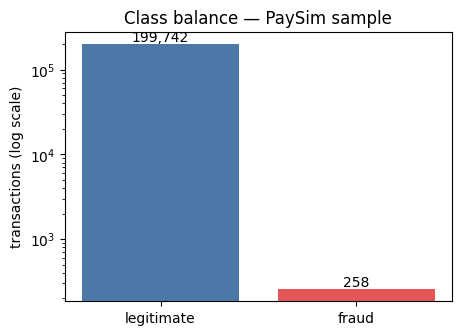

In [7]:
counts = df["isFraud"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["legitimate", "fraud"], counts.values, color=["#4C78A8", "#E45756"])
ax.set_yscale("log")
ax.set_ylabel("transactions (log scale)")
ax.set_title("Class balance — PaySim sample")
for i, value in enumerate(counts.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")
plt.show()

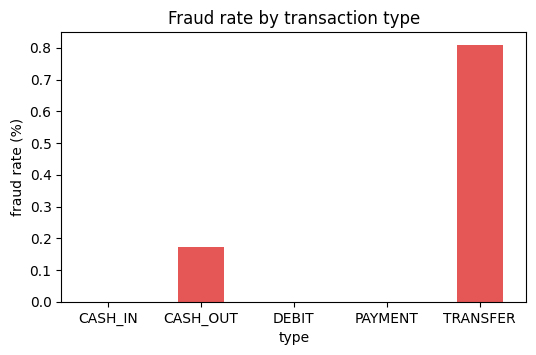

In [8]:
rate = df.groupby("type", observed=True)["isFraud"].mean().mul(100)
fig, ax = plt.subplots(figsize=(6, 3.5))
rate.plot(kind="bar", ax=ax, color="#E45756")
ax.set_ylabel("fraud rate (%)")
ax.set_title("Fraud rate by transaction type")
plt.xticks(rotation=0)
plt.show()

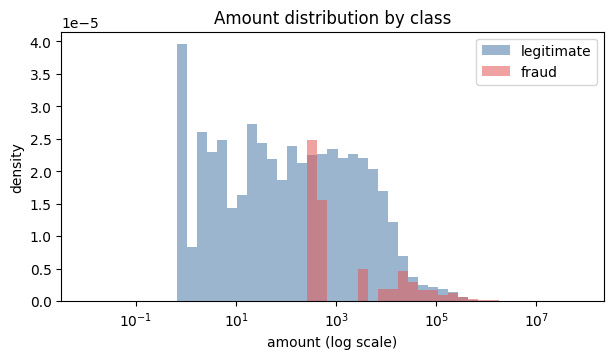

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.logspace(np.log10(0.01), np.log10(df["amount"].max()), 50)
for label, name, color in [(0, "legitimate", "#4C78A8"), (1, "fraud", "#E45756")]:
    values = df.loc[df.isFraud == label, "amount"].clip(lower=0.01)
    ax.hist(values, bins=bins, alpha=0.55, label=name, color=color, density=True)
ax.set_xscale("log")
ax.set_xlabel("amount (log scale)")
ax.set_ylabel("density")
ax.set_title("Amount distribution by class")
ax.legend()
plt.show()

## Balance consistency

In [10]:
consistent = (df["newbalanceOrig"] - (df["oldbalanceOrg"] - df["amount"])).abs() <= 0.01
print(f"consistent rows: {consistent.mean()*100:.2f}%")
(
    df.assign(consistent=consistent)
      .groupby("type", observed=True)["consistent"]
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
)

consistent rows: 20.23%


type
DEBIT       69.29
PAYMENT     45.85
CASH_OUT    11.04
TRANSFER     4.53
CASH_IN      0.00
Name: consistent, dtype: float64

## The trivial rule

In [11]:
rule = (df["amount"] == df["oldbalanceOrg"]) & df["type"].isin(["TRANSFER", "CASH_OUT"])
print(f"selected rows: {int(rule.sum()):,}")
print(f"fraud among them: {int(df.loc[rule, 'isFraud'].sum()):,} ({df.loc[rule, 'isFraud'].mean()*100:.2f}%)")
print(f"share of all frauds: {df.loc[rule, 'isFraud'].sum() / df.isFraud.sum() * 100:.2f}%")

selected rows: 257
fraud among them: 257 (100.00%)
share of all frauds: 99.61%


## Account identity

In [12]:
orig_counts = df["nameOrig"].value_counts()
print(f"unique nameOrig: {orig_counts.size:,}")
print(f"appear once: {(orig_counts == 1).mean()*100:.2f}%")
print(f"max occurrences: {orig_counts.max()}")
print(f"unique nameDest: {df['nameDest'].nunique():,}")

unique nameOrig: 199,991
appear once: 100.00%
max occurrences: 2
unique nameDest: 174,536


## Key takeaways (sample)

The full-data numbers are in `ml/training/docs/eda_report.md`:

- fraud is ~0.13% and exists only in `TRANSFER` / `CASH_OUT`;
- `amount == oldbalanceOrg` is a near-perfect fraud rule — the simulator's main weakness;
- balance arithmetic is inconsistent on most rows;
- 99.85% of `nameOrig` accounts appear once (no sender history).

Next: preprocessing module, temporal split + calibration split, then the Logistic Regression baseline.

In [13]:
# Optional: load the full dataset (6.36M rows, ~534 MB in memory)
# full = load_paysim()